In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df=pd.read_csv("/content/Sales_Analysis_Dataset.csv")
df.head()

,Order_ID,Order_Date,Customer_ID,Region,City,Category,Product,Quantity,Unit_Price_INR,Discount,Sales_INR,Cost_INR,Profit_INR,Payment_Method,Customer_Segment
0,ORD1368,2025-01-01,CUST1092,North,Chandigarh,Electronics,Mobile,5,22000,0.05,104500.0,82500,22000.0,Debit Card,Small Business
1,ORD1699,2025-01-01,CUST1133,East,Bhubaneswar,Electronics,Headphones,7,1800,0.15,10710.0,6650,4060.0,Credit Card,Consumer
2,ORD1324,2025-01-02,CUST1091,South,Hyderabad,Stationery,Pen Pack,5,120,0.10,540.0,275,265.0,Net Banking,Consumer
3,ORD1642,2025-01-02,CUST1053,East,Kolkata,Stationery,Pen Pack,1,120,0.00,120.0,55,65.0,Net Banking,Consumer
4,ORD1130,2025-01-02,CUST1066,Central,Nagpur,Electronics,Headphones,4,1800,0.05,6840.0,3800,3040.0,Debit Card,Consumer


In [4]:
df.shape

(750, 15)

In [11]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Region', 'City', 'Category',
       'Product', 'Quantity', 'Unit_Price_INR', 'Discount', 'Sales_INR',
       'Cost_INR', 'Profit_INR', 'Payment_Method', 'Customer_Segment'],
      dtype='object')

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 750 entries, 0 to 749
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          750 non-null    object 
 1   Order_Date        750 non-null    object 
 2   Customer_ID       750 non-null    object 
 3   Region            750 non-null    object 
 4   City              750 non-null    object 
 5   Category          750 non-null    object 
 6   Product           750 non-null    object 
 7   Quantity          750 non-null    int64  
 8   Unit_Price_INR    750 non-null    int64  
 9   Discount          750 non-null    float64
 10  Sales_INR         750 non-null    float64
 11  Cost_INR          750 non-null    int64  
 12  Profit_INR        750 non-null    float64
 13  Payment_Method    750 non-null    object 
 14  Customer_Segment  750 non-null    object 
dtypes: float64(3), int64(3), object(9)
memory usage: 88.0+ KB


In [14]:
df.isnull().sum()

,0
Order_ID,0
Order_Date,0
Customer_ID,0
Region,0
City,0
Category,0
Product,0
Quantity,0
Unit_Price_INR,0
Discount,0


In [15]:
df.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
745,False
746,False
747,False
748,False


In [16]:
df.describe()

,Quantity,Unit_Price_INR,Discount,Sales_INR,Cost_INR,Profit_INR
count,750.000000,750.000000,750.000000,750.000000,750.000000,750.000000
mean,4.045333,10374.053333,0.066733,40023.632667,32162.306667,7861.326000
std,2.011469,17235.532757,0.061982,76767.106430,62926.071114,14918.389731
min,1.000000,80.000000,0.000000,72.000000,35.000000,37.000000
25%,2.000000,450.000000,0.000000,840.000000,440.000000,413.000000
50%,4.000000,900.000000,0.050000,4860.000000,2880.000000,1740.000000
75%,6.000000,8500.000000,0.100000,41587.500000,32900.000000,7375.000000
max,7.000000,55000.000000,0.200000,385000.000000,294000.000000,91000.000000


In [18]:
product_sales = df.groupby("Product")["Sales_INR"].sum()

print(product_sales.sort_values(ascending=False))

Product
Laptop          17971250.0
Mobile           7075200.0
Desk             2239325.0
Office Chair     1658150.0
Headphones        479610.0
Keyboard          306315.0
Mouse             121742.5
Water Bottle      106020.0
Pen Pack           36060.0
Notebook           24052.0
Name: Sales_INR, dtype: float64


In [19]:
product_profit = df.groupby("Product")["Profit_INR"].sum()

print(product_profit.sort_values(ascending=False))

Product
Laptop          3187250.0
Mobile          1448700.0
Desk             419325.0
Office Chair     360950.0
Headphones       205060.0
Keyboard         133515.0
Mouse             60122.5
Water Bottle      49920.0
Pen Pack          18405.0
Notebook          12747.0
Name: Profit_INR, dtype: float64


In [20]:
region_sales = df.groupby("Region")["Sales_INR"].sum()

print(region_sales.sort_values(ascending=False))

Region
West       7094558.0
North      6180140.0
East       6035260.0
Central    5454362.0
South      5253404.5
Name: Sales_INR, dtype: float64


In [21]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

df["Month"] = df["Order_Date"].dt.month_name()

monthly_sales = df.groupby("Month")["Sales_INR"].sum()

print(monthly_sales.sort_values(ascending=False))

Month
July         3514346.0
October      3440871.5
December     3246238.0
March        2917784.5
February     2731963.0
November     2472880.5
August       2302883.0
May          2256967.0
April        2199658.0
June         1991484.5
September    1622709.0
January      1319939.5
Name: Sales_INR, dtype: float64


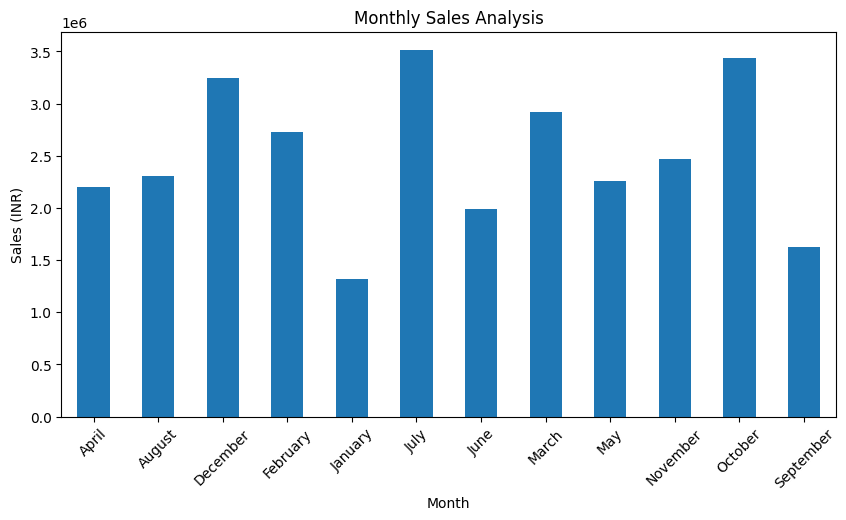

In [22]:
import matplotlib.pyplot as plt

monthly_sales.plot(kind="bar", figsize=(10,5))

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45)
plt.show()

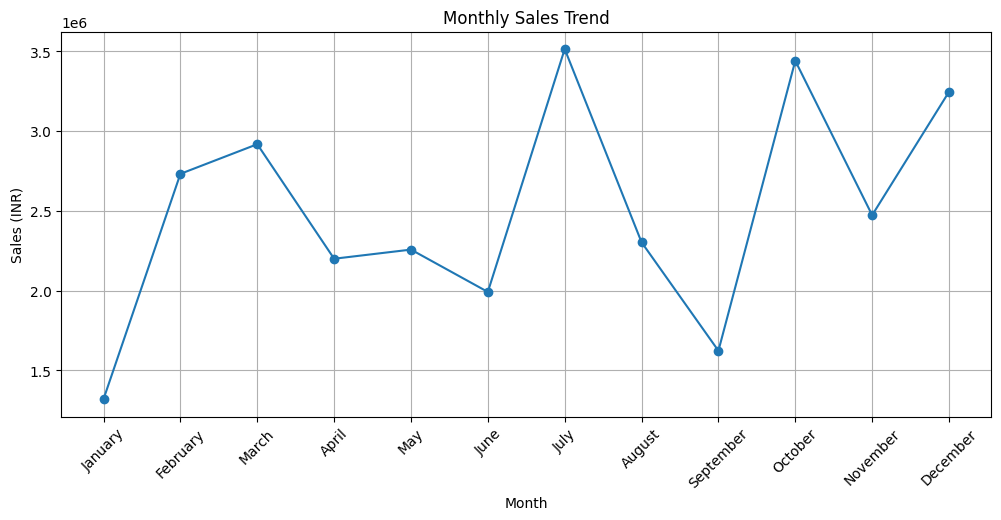

In [23]:
month_order = [
      "January", "February", "March", "April",
          "May", "June", "July", "August",
              "September", "October", "November", "December"
              ]

monthly_sales = df.groupby("Month")["Sales_INR"].sum()
monthly_sales = monthly_sales.reindex(month_order)

plt.figure(figsize=(12,5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (INR)")
plt.xticks(rotation=45)
plt.grid()
plt.show()


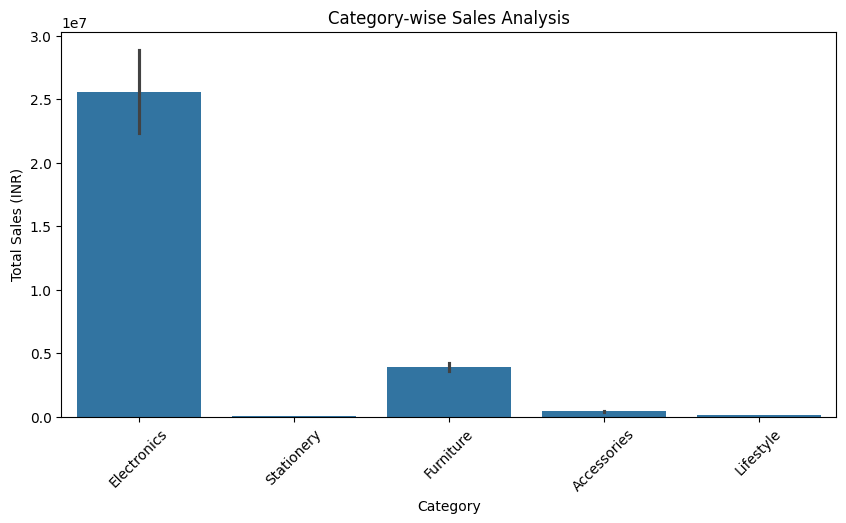

In [26]:
plt.figure(figsize=(10,5))

sns.barplot(
    data=df,
        x="Category",
            y="Sales_INR",
                estimator=sum
                )

plt.title("Category-wise Sales Analysis")
plt.xlabel("Category")
plt.ylabel("Total Sales (INR)")
plt.xticks(rotation=45)

plt.show()

In [27]:
df.groupby("Category")["Profit_INR"].sum().sort_values(ascending=False)

,Profit_INR
Category,
Electronics,4841010.0
Furniture,780275.0
Accessories,193637.5
Lifestyle,49920.0
Stationery,31152.0


In [28]:
df.groupby("Product")["Quantity"].sum().sort_values(ascending=False)

,Quantity
Product,
Keyboard,360
Laptop,352
Mobile,341
Notebook,323
Pen Pack,321
Headphones,289
Desk,280
Office Chair,276
Water Bottle,255


In [29]:
df.groupby("Product")["Discount"].mean().sort_values(ascending=False)

,Discount
Product,
Office Chair,0.076471
Water Bottle,0.072857
Headphones,0.071831
Laptop,0.070833
Notebook,0.069481
Mouse,0.065625
Pen Pack,0.063924
Desk,0.062879
Mobile,0.059412


In [30]:
print("Total Sales:", df["Sales_INR"].sum())
print("Total Profit:", df["Profit_INR"].sum())
print("Total Quantity:", df["Quantity"].sum())
print("Average Sales:", df["Sales_INR"].mean())

Total Sales: 30017724.5
Total Profit: 5895994.5
Total Quantity: 3034
Average Sales: 40023.632666666665
